# Fourier Analysis Demo
Showcase of base experiments to analyse Fourier space of solution

## 0 - Setup

In [1]:
import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN
from src.pde     import HeatEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import (
    plot_training_history,
    plot_solution_comparison,
    plot_power_spectrum,
    plot_mode_l2_errors,
    plot_frequency_sweep,
    plot_multi_model_l2_error
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## 1 - Frequency Sweep
Train both models on heat equatin over a range of IC frequencies

In [2]:
FREQUENCIES = [0.5, 1.0, 1.5, 2, 2.5, 3, 3.5]

In [3]:
sweep_results = {"qpinn": [], "classical": []}
for freq in FREQUENCIES:
    pde = HeatEquation(freq=freq)
    print(f"\n{'='*60}\nfreq = {freq}")

    # --- QPINN ---
    qpinn = MerlinHeatQPINN().to(device)
    train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=100)
    metrics, _, _, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)
    sweep_results["qpinn"].append({"frequency": freq, "rel_l2": metrics["rel_l2"]})
    print(f"  QPINN      rel_l2 = {metrics['rel_l2']:.4e}")

    # --- Classical ---
    classical = ClassicalHeatQPINN().to(device)
    train(model=classical, pde=pde, loss_fn=total_loss, log_every=100)
    metrics, _, _, _, _ = evaluate(model=classical, pde=pde, device=device, dtype=dtype)
    sweep_results["classical"].append({"frequency": freq, "rel_l2": metrics["rel_l2"]})
    print(f"  Classical  rel_l2 = {metrics['rel_l2']:.4e}")



freq = 0.5
Parameters — total: 270  trainable: 270

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 8.8293e+00 | PDE: 1.15e-05 | Cons: 1.33e-01 | IC: 8.71e-01 | BC: 1.05e-01 | Time: 0.3s
Epoch   100/300 | Loss: 2.7017e-01 | PDE: 5.62e-02 | Cons: 1.42e+00 | IC: 3.32e-03 | BC: 3.89e-02 | Time: 25.6s
Epoch   200/300 | Loss: 1.4680e-02 | PDE: 5.54e-03 | Cons: 5.63e-02 | IC: 1.38e-04 | BC: 2.14e-03 | Time: 48.5s
Epoch   300/300 | Loss: 4.8525e-03 | PDE: 1.96e-03 | Cons: 2.64e-02 | IC: 1.76e-05 | BC: 8.13e-05 | Time: 73.7s

Done — 73.7s total
Evaluating on 300×300 grid …
  Relative L2 : 1.1658e-02
  MAE         : 6.0242e-03
  Max abs err : 2.6816e-02
  RMSE        : 7.3117e-03
  QPINN      rel_l2 = 1.1658e-02
Parameters — total: 250  trainable: 250

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 3.0949e+00 | PDE: 4.95e-05 | Cons: 3.65e-03 | IC: 3.02e-01 | BC: 7.92e-02 | Time: 0.0s
Epoch   100/300 | Loss: 1.3091e+00 | PDE: 1.61e-01

Saved: figures/fourier_demo/freq_sweep.png


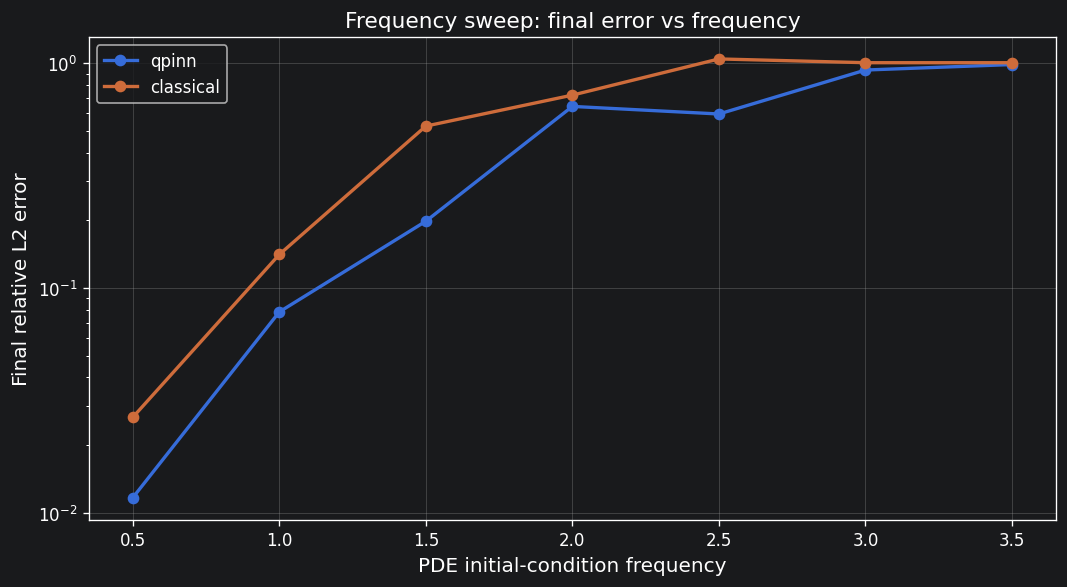

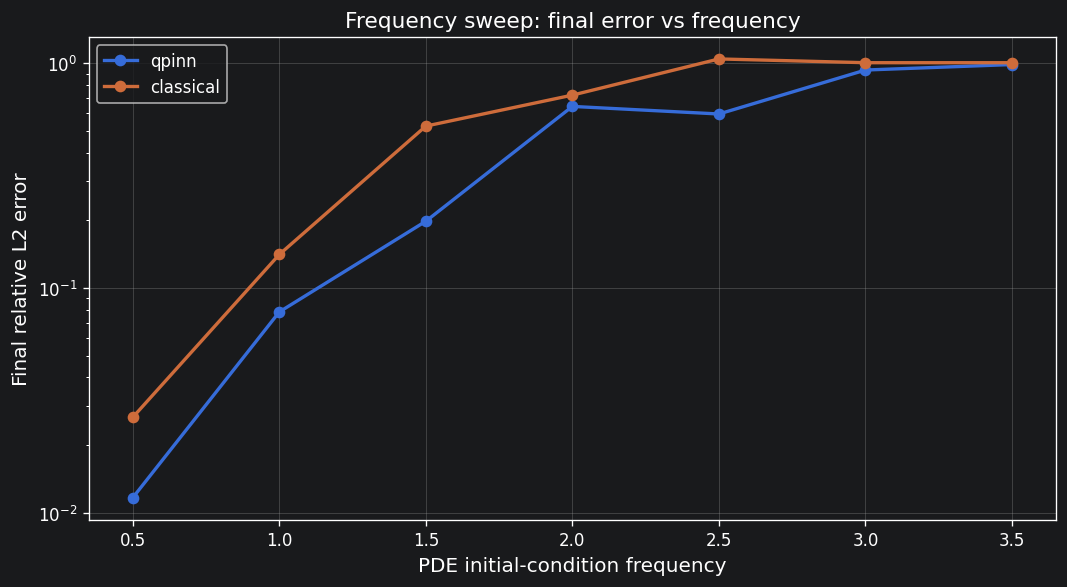

In [4]:
plot_frequency_sweep(
    sweep_results,
    save_path = "figures/fourier_demo/freq_sweep.png",
    show      = True,
)

## 2 - Train both models with same frequency and compare

In [2]:
FREQUENCY = 0.5

In [3]:

ref_pde = HeatEquation(freq=FREQUENCY)

# QPINN
qpinn_ref = MerlinHeatQPINN().to(device)
history_q = train(model=qpinn_ref, pde=ref_pde, epochs = 600)

# Classical
classical_ref = ClassicalHeatQPINN().to(device)
history_c = train(model=classical_ref, pde=ref_pde, epochs = 600)

Parameters — total: 270  trainable: 270

Training for 600 epochs on cpu  (dtype=torch.float32)
Epoch     1/600 | Loss: 5.0112e+00 | PDE: 3.56e-04 | Cons: 2.82e-02 | IC: 5.01e-01 | BC: 2.78e-04 | Time: 0.1s
Epoch    50/600 | Loss: 1.2564e+00 | PDE: 4.15e-02 | Cons: 2.34e-02 | IC: 9.15e-02 | BC: 2.97e-01 | Time: 4.7s
Epoch   100/600 | Loss: 2.7847e-01 | PDE: 4.37e-02 | Cons: 1.50e+00 | IC: 3.09e-03 | BC: 5.44e-02 | Time: 9.5s
Epoch   150/600 | Loss: 1.8841e-01 | PDE: 1.66e-02 | Cons: 1.21e+00 | IC: 3.01e-03 | BC: 2.12e-02 | Time: 14.3s
Epoch   200/600 | Loss: 1.9172e-02 | PDE: 2.59e-03 | Cons: 1.16e-01 | IC: 1.91e-04 | BC: 3.05e-03 | Time: 18.8s
Epoch   250/600 | Loss: 9.5893e-03 | PDE: 8.69e-04 | Cons: 6.58e-02 | IC: 1.94e-04 | BC: 2.02e-04 | Time: 23.2s
Epoch   300/600 | Loss: 7.6837e-03 | PDE: 1.49e-03 | Cons: 4.29e-02 | IC: 1.71e-04 | BC: 1.97e-04 | Time: 27.7s
Epoch   350/600 | Loss: 4.1445e-03 | PDE: 5.72e-04 | Cons: 2.60e-02 | IC: 4.74e-05 | BC: 4.98e-04 | Time: 32.2s
Epoch   400/

In [4]:
# Evaluate models
grid_n = 60


_, U_pred_q, U_true, x_grid, t_grid = evaluate(model=qpinn_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_c, _,      _,      _      = evaluate(model=classical_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

Evaluating on 60×60 grid …
  Relative L2 : 1.9996e-02
  MAE         : 1.1049e-02
  Max abs err : 2.6932e-02
  RMSE        : 1.2459e-02
Evaluating on 60×60 grid …
  Relative L2 : 2.8706e-02
  MAE         : 1.6596e-02
  Max abs err : 3.7260e-02
  RMSE        : 1.7886e-02


#TODO : figure out here Q error is smaller than C error ??? this doesnt match results from other pipeline

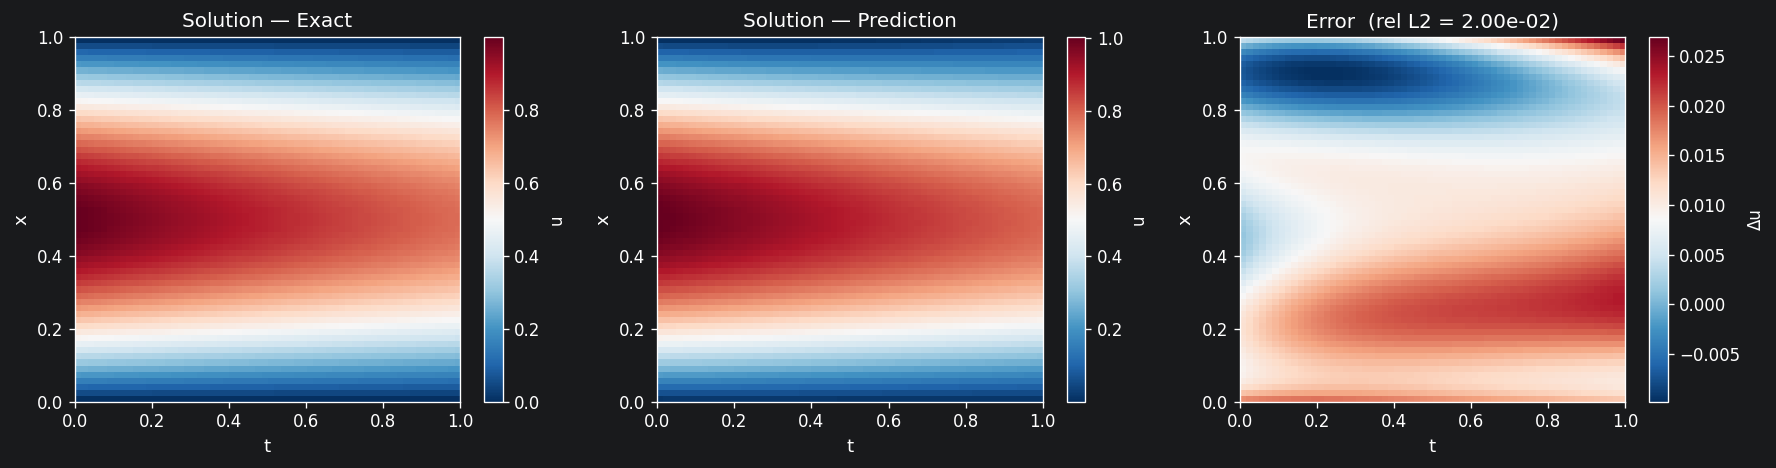

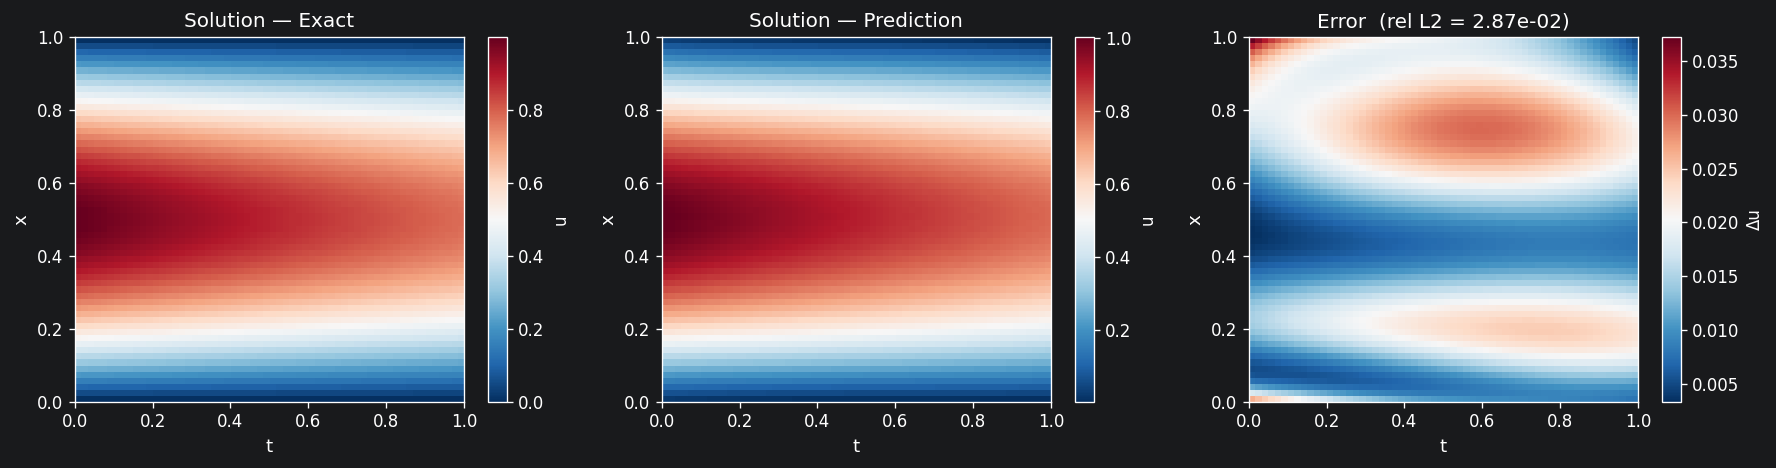

(<Figure size 1800x480 with 6 Axes>, 0.028705952689051628)

In [5]:
plot_solution_comparison(U_pred_q,U_true)
plot_solution_comparison(U_pred_c,U_true)


### 2.1 - Compare power spectra

QPINN power spectrum
Saved: ../figures/demo_fourier/power_spectrum_q.png


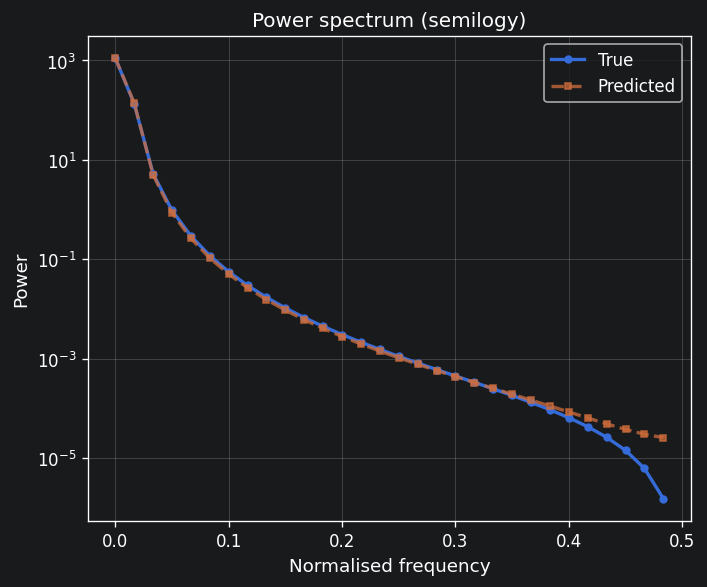

Classical power spectrum
Saved: ../figures/demo_fourier/power_spectrum_c.png


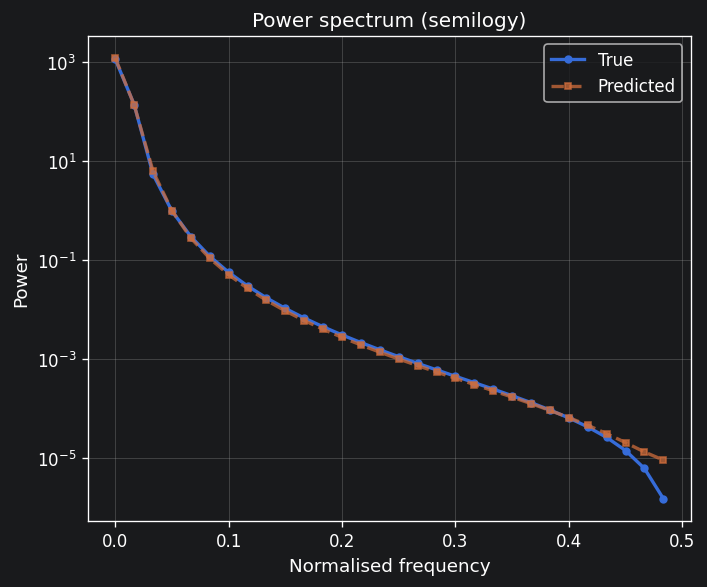

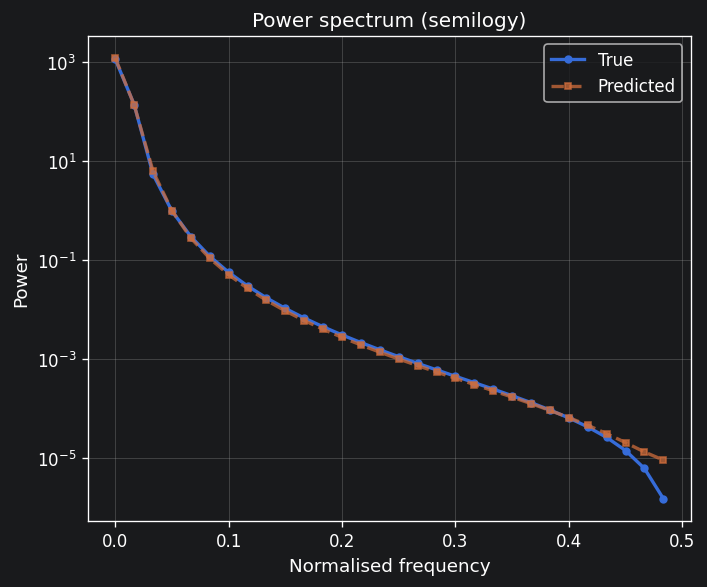

In [6]:
print("QPINN power spectrum")
plot_power_spectrum(U_pred_q, U_true, save_path="../figures/demo_fourier/power_spectrum_q.png", exclude_0_mode=False)

print("Classical power spectrum")
plot_power_spectrum(U_pred_c, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

### 2.2 Compare per-mode L2 error

QPINN mode errors
Saved: figures/fourier_demo/l2_error_Q.png


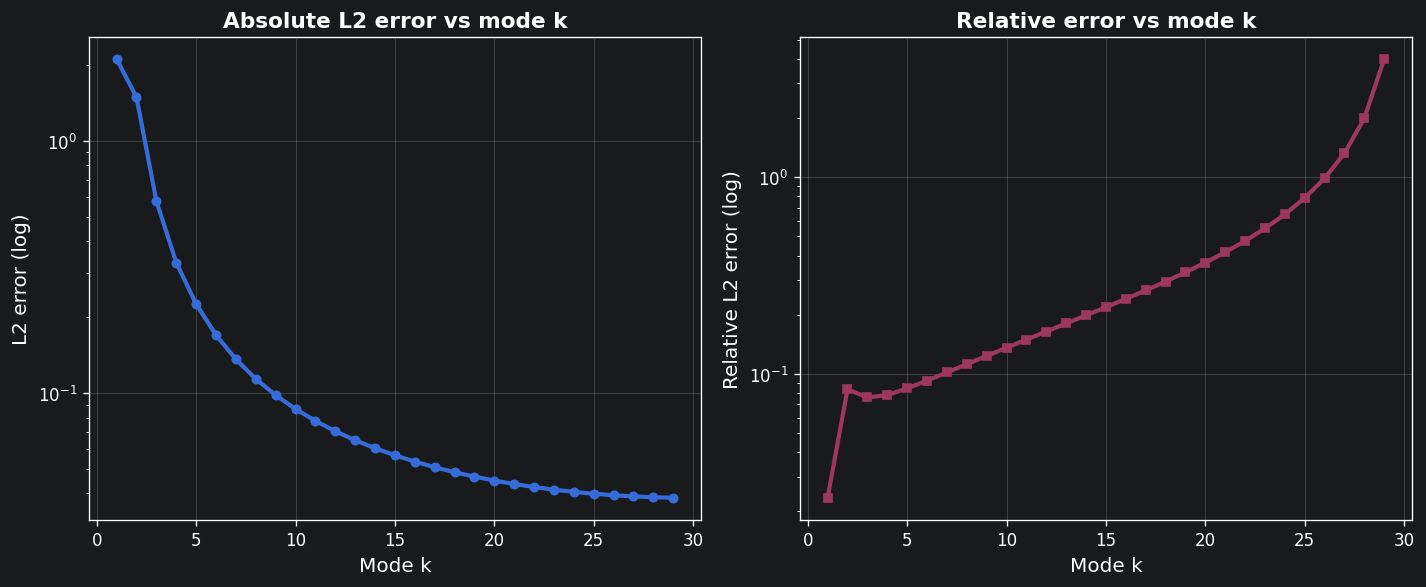

Classical mode errors
Saved: figures/fourier_demo/l2_error_C.png


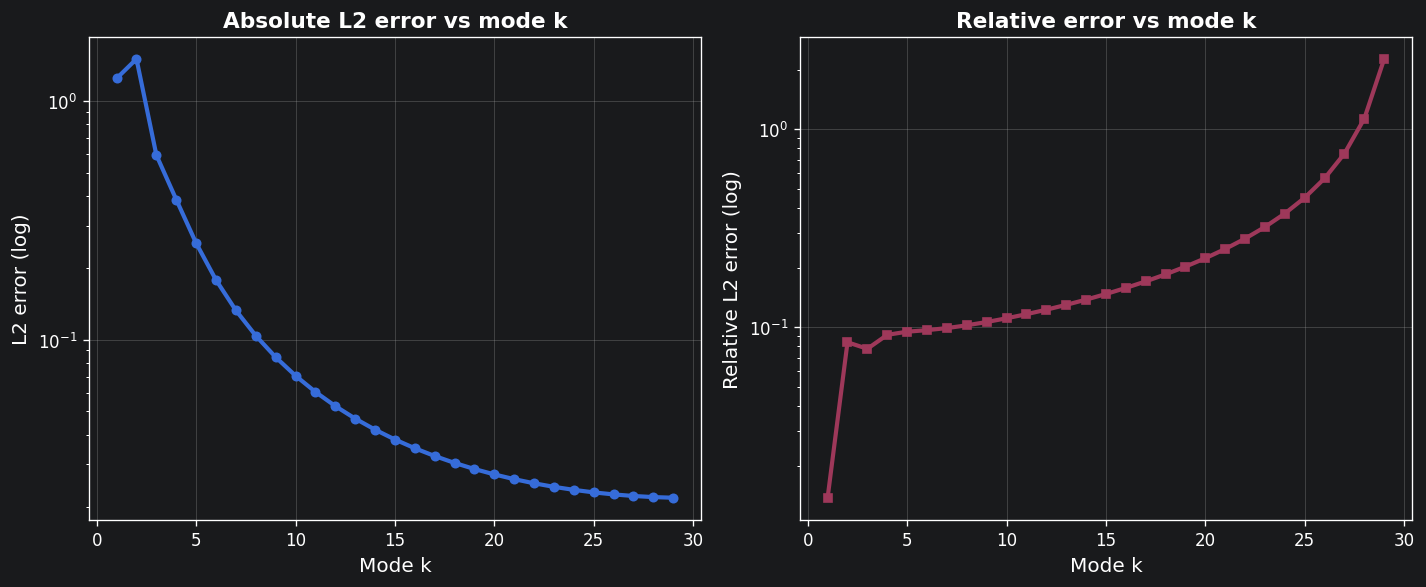

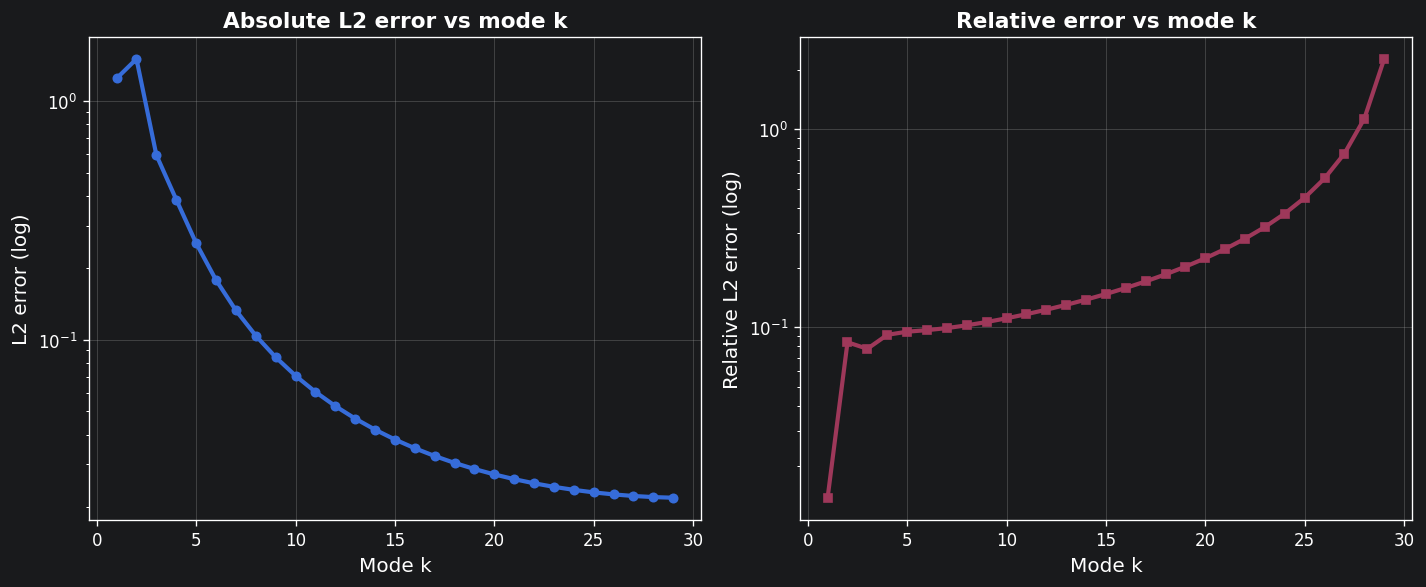

In [7]:
print("QPINN mode errors")
plot_mode_l2_errors(U_pred_q, U_true,
                    save_path="figures/fourier_demo/l2_error_Q.png")

print("Classical mode errors")
plot_mode_l2_errors(U_pred_c, U_true,
                    save_path="figures/fourier_demo/l2_error_C.png")

## Compare directly

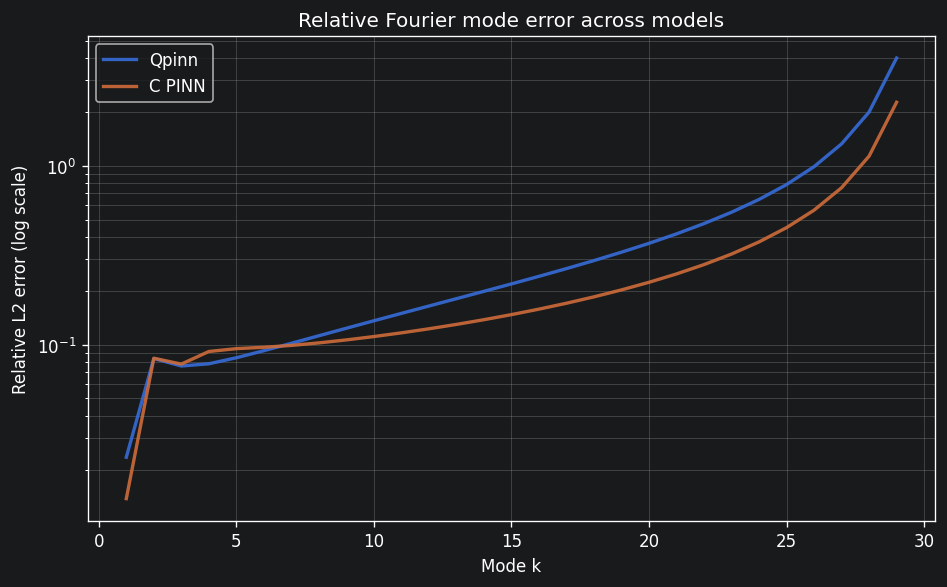

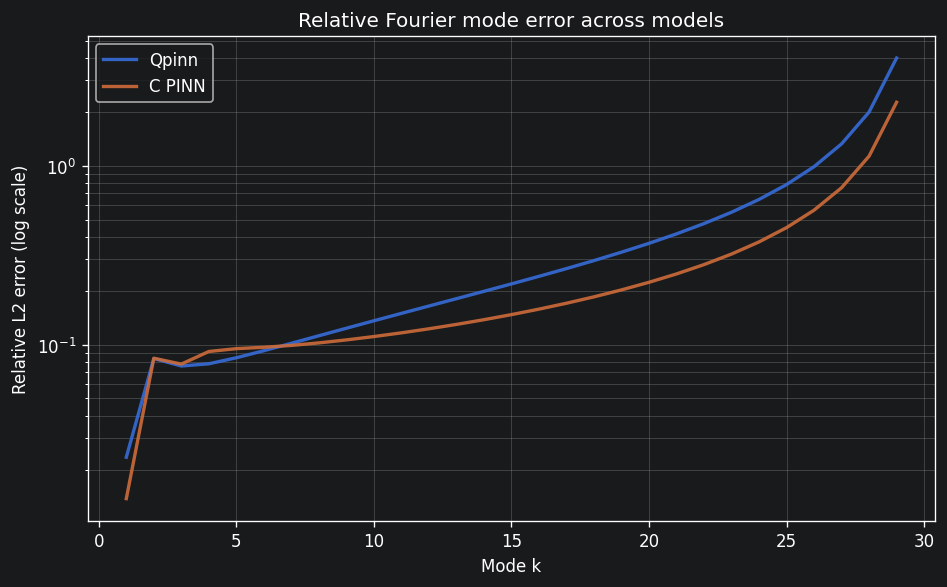

In [8]:


plot_multi_model_l2_error(U_true, [U_pred_q, U_pred_c],["Qpinn", "C PINN"])